In [25]:
# Install gdown to download the dataset from Google Drive easily
!pip install -q gdown

In [26]:
import os
import gdown
import zipfile

# Google Drive file ID from the provided link
file_id = '1NMJ0FOxcWH1mwFFeERuY6fgEY-MVgeET'
url = f'https://drive.google.com/uc?id={file_id}'
output = 'avocado_dataset.zip'

# Download dataset
if not os.path.exists(output):
    print("Downloading dataset...")
    gdown.download(url, output, quiet=False)
else:
    print("Dataset zip already downloaded.")

# Extract dataset
extract_path = 'avocado_data'
if not os.path.exists(extract_path):
    print("Extracting dataset...")
    with zipfile.ZipFile(output, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("Extraction completed!")
else:
    print("Dataset already extracted.")

Dataset zip already downloaded.
Dataset already extracted.


In [27]:
# Explore the directory structure of the extracted dataset
for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, '').count(os.sep)
    indent = ' ' * 4 * (level)
    print(f"{indent}{os.path.basename(root)}/ - {len(files)} files")

avocado_data/ - 0 files
    test/ - 0 files
        canker/ - 22 files
        fresh/ - 33 files
        blackspot/ - 22 files
        grenning/ - 22 files
    train/ - 0 files
        canker/ - 179 files
        fresh/ - 281 files
        blackspot/ - 184 files
        grenning/ - 347 files


## 1. Understanding of the Dataset
We will inspect the classes, calculate the exact count of samples per class in both training and test sets, identify potential class imbalances, check image dimensions, and visualize sample images from each category.

Class distribution stats:
       Class  Train  Test  Total
0  blackspot    184    22    206
1     canker    179    22    201
2      fresh    281    33    314
3   grenning    347    22    369


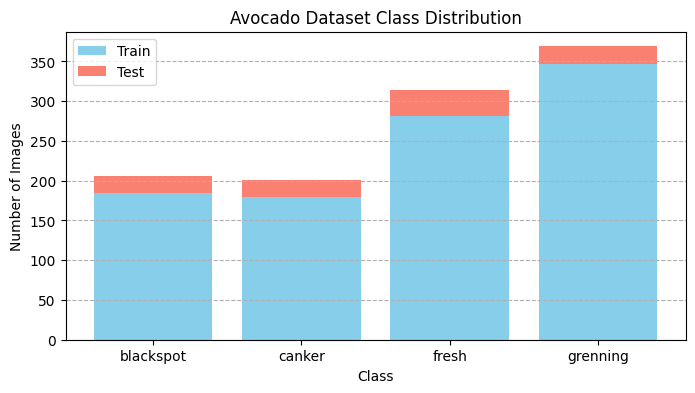

In [28]:
import os
import glob
import cv2
import pandas as pd
import matplotlib.pyplot as plt

train_dir = 'avocado_data/train'
test_dir = 'avocado_data/test'
classes = sorted(os.listdir(train_dir))

# Count images per class
stats = []
for cls in classes:
    train_count = len(os.listdir(os.path.join(train_dir, cls)))
    test_count = len(os.listdir(os.path.join(test_dir, cls)))
    stats.append({'Class': cls, 'Train': train_count, 'Test': test_count, 'Total': train_count + test_count})

df_stats = pd.DataFrame(stats)
print("Class distribution stats:")
print(df_stats)

# Visualize class distribution
plt.figure(figsize=(8, 4))
plt.bar(df_stats['Class'], df_stats['Train'], label='Train', color='skyblue')
plt.bar(df_stats['Class'], df_stats['Test'], bottom=df_stats['Train'], label='Test', color='salmon')
plt.title('Avocado Dataset Class Distribution')
plt.xlabel('Class')
plt.ylabel('Number of Images')
plt.legend()
plt.grid(axis='y', linestyle='--')
plt.show()

Sample unique image dimensions found: [(254, 306, 3), (198, 196, 3), (344, 368, 3), (800, 800, 3), (158, 174, 3)]


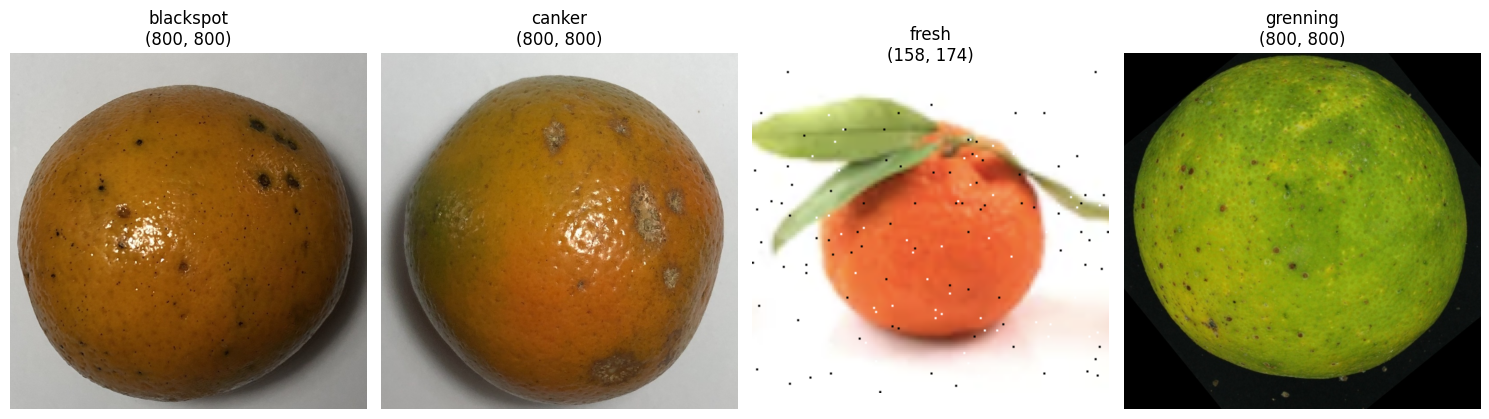

In [29]:
# Analyze image shapes and display samples
sizes = []
for cls in classes:
    paths = glob.glob(os.path.join(train_dir, cls, '*'))[:10]
    for p in paths:
        img = cv2.imread(p)
        if img is not None:
            sizes.append(img.shape)

print(f"Sample unique image dimensions found: {list(set(sizes))[:5]}")

# Display a sample from each class
fig, axes = plt.subplots(1, len(classes), figsize=(15, 5))
for i, cls in enumerate(classes):
    img_path = glob.glob(os.path.join(train_dir, cls, '*'))[0]
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    axes[i].imshow(img)
    axes[i].set_title(f"{cls}\n{img.shape[:2]}")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

## 1. Understanding of the Dataset
We will inspect the classes, calculate the exact count of samples per class in both training and test sets, look for class imbalance, check image dimensions, and visualize sample images from each category.

Class distribution stats:
       Class  Train  Test  Total
0  blackspot    184    22    206
1     canker    179    22    201
2      fresh    281    33    314
3   grenning    347    22    369


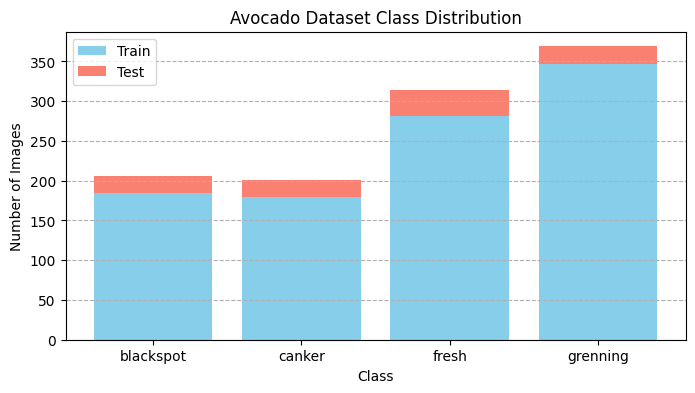

In [30]:
import os
import glob
import cv2
import pandas as pd
import matplotlib.pyplot as plt

train_dir = 'avocado_data/train'
test_dir = 'avocado_data/test'
classes = sorted(os.listdir(train_dir))

# Count images per class
stats = []
for cls in classes:
    train_count = len(os.listdir(os.path.join(train_dir, cls)))
    test_count = len(os.listdir(os.path.join(test_dir, cls)))
    stats.append({'Class': cls, 'Train': train_count, 'Test': test_count, 'Total': train_count + test_count})

df_stats = pd.DataFrame(stats)
print("Class distribution stats:")
print(df_stats)

# Visualize class distribution
plt.figure(figsize=(8, 4))
plt.bar(df_stats['Class'], df_stats['Train'], label='Train', color='skyblue')
plt.bar(df_stats['Class'], df_stats['Test'], bottom=df_stats['Train'], label='Test', color='salmon')
plt.title('Avocado Dataset Class Distribution')
plt.xlabel('Class')
plt.ylabel('Number of Images')
plt.legend()
plt.grid(axis='y', linestyle='--')
plt.show()

Sample unique image dimensions found: [(254, 306, 3), (198, 196, 3), (344, 368, 3), (800, 800, 3), (158, 174, 3)]


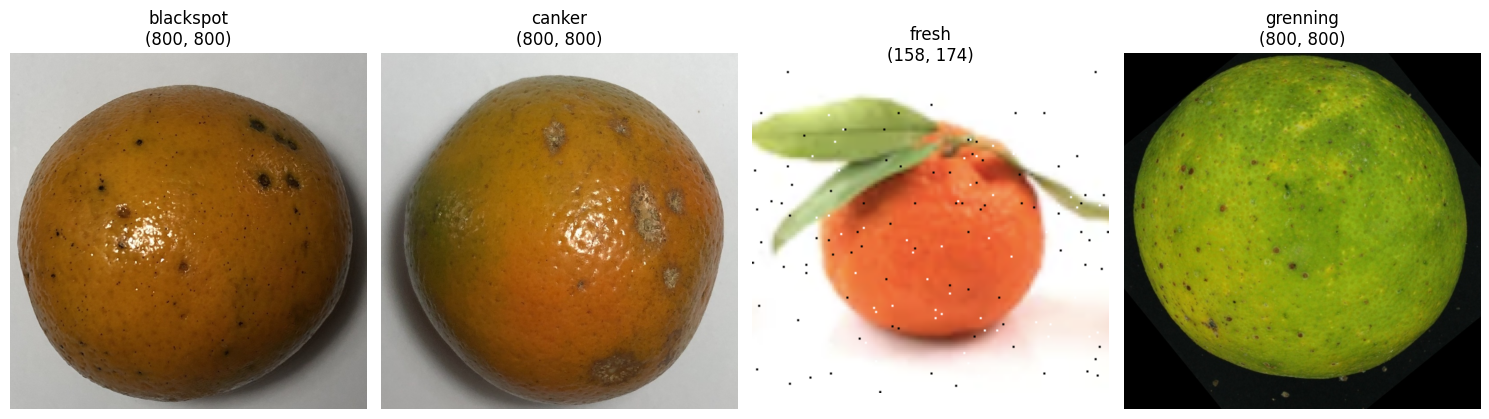

In [31]:
# Analyze image shapes and display samples
sizes = []
for cls in classes:
    paths = glob.glob(os.path.join(train_dir, cls, '*'))[:10]
    for p in paths:
        img = cv2.imread(p)
        if img is not None:
            sizes.append(img.shape)

print(f"Sample unique image dimensions found: {list(set(sizes))[:5]}")

# Display a sample from each class
fig, axes = plt.subplots(1, len(classes), figsize=(15, 5))
for i, cls in enumerate(classes):
    img_path = glob.glob(os.path.join(train_dir, cls, '*'))[0]
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    axes[i].imshow(img)
    axes[i].set_title(f"{cls}\n{img.shape[:2]}")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

## 1. Understanding of the Dataset
We will inspect the classes, calculate the exact count of samples per class in both training and test sets, look for class imbalance, check image dimensions, and visualize sample images from each category.

Class distribution stats:
       Class  Train  Test  Total
0     canker    179    22    201
1      fresh    281    33    314
2  blackspot    184    22    206
3   grenning    347    22    369


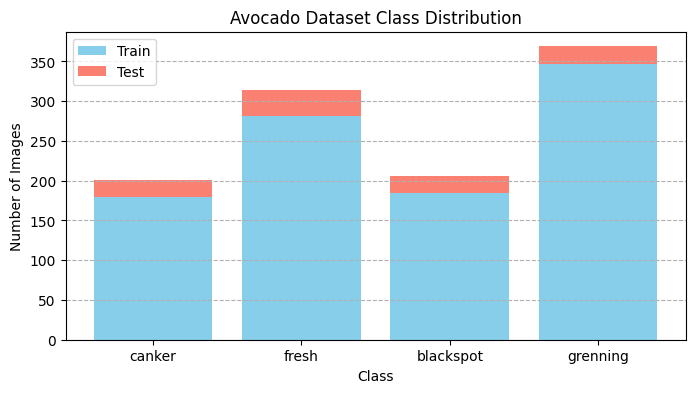

In [32]:
import matplotlib.pyplot as plt
import cv2
import pandas as pd
import glob

train_dir = 'avocado_data/train'
test_dir = 'avocado_data/test'

# Count images per class
classes = os.listdir(train_dir)
stats = []

for cls in classes:
    train_count = len(os.listdir(os.path.join(train_dir, cls)))
    test_count = len(os.listdir(os.path.join(test_dir, cls)))
    stats.append({'Class': cls, 'Train': train_count, 'Test': test_count, 'Total': train_count + test_count})

df_stats = pd.DataFrame(stats)
print("Class distribution stats:")
print(df_stats)

# Visualize class distribution
plt.figure(figsize=(8, 4))
plt.bar(df_stats['Class'], df_stats['Train'], label='Train', color='skyblue')
plt.bar(df_stats['Class'], df_stats['Test'], bottom=df_stats['Train'], label='Test', color='salmon')
plt.title('Avocado Dataset Class Distribution')
plt.xlabel('Class')
plt.ylabel('Number of Images')
plt.legend()
plt.grid(axis='y', linestyle='--')
plt.show()

In [33]:
# Fix the set indexing error by converting it to a list first
sizes = []
for cls in classes:
    paths = glob.glob(os.path.join(train_dir, cls, '*'))[:10]
    for p in paths:
        img = cv2.imread(p)
        if img is not None:
            sizes.append(img.shape)

print(f"Sample of image dimensions: {list(set(sizes))[:10]}")

Sample of image dimensions: [(254, 306, 3), (198, 196, 3), (344, 368, 3), (800, 800, 3), (158, 174, 3), (362, 464, 3), (346, 332, 3), (258, 314, 3), (350, 390, 3), (176, 144, 3)]


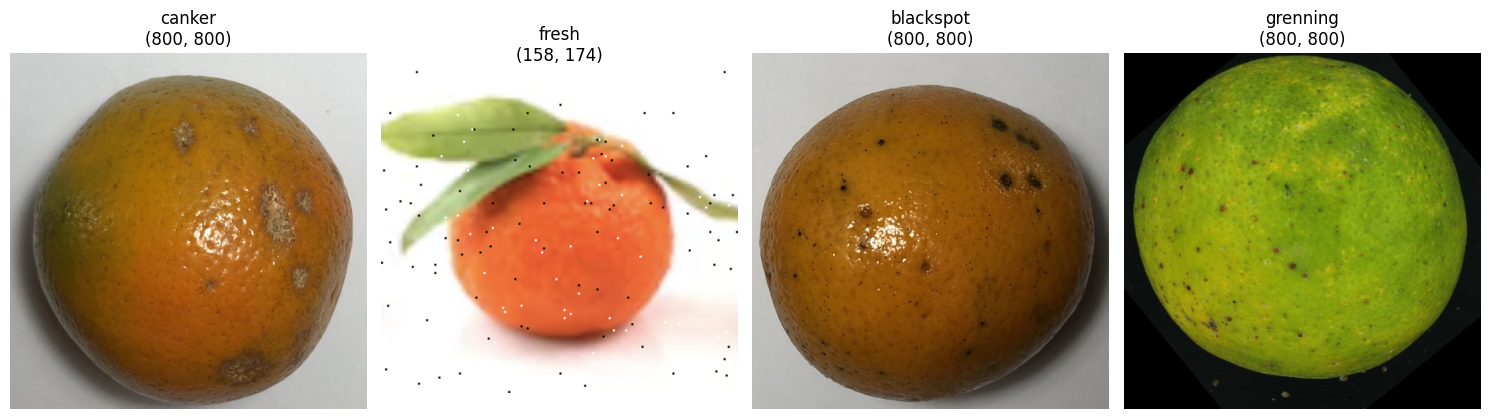

In [34]:
# Display sample images from each category
fig, axes = plt.subplots(1, len(classes), figsize=(15, 5))
for i, cls in enumerate(classes):
    img_path = glob.glob(os.path.join(train_dir, cls, '*'))[0]
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    axes[i].imshow(img)
    axes[i].set_title(f"{cls}\n{img.shape[:2]}")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

## 2. Approach 1: Classical Image Processing + Machine Learning (Random Forest)
Here we extract color statistics (Mean, Std Dev in HSV and RGB color spaces) and texture features (Local Binary Patterns) from the avocados to train a classic machine learning model.

In [35]:
import numpy as np
from skimage.feature import local_binary_pattern
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
import cv2
import os
import glob

def extract_features(img_path):
    img = cv2.imread(img_path)
    if img is None:
        return None
    img_resized = cv2.resize(img, (128, 128))

    # Color features: mean and std of RGB and HSV channels
    hsv = cv2.cvtColor(img_resized, cv2.COLOR_BGR2HSV)
    rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)

    color_feats = []
    for i in range(3):
        color_feats.append(np.mean(rgb[:,:,i]))
        color_feats.append(np.std(rgb[:,:,i]))
        color_feats.append(np.mean(hsv[:,:,i]))
        color_feats.append(np.std(hsv[:,:,i]))

    # Texture features: Local Binary Patterns on grayscale image
    gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)
    lbp = local_binary_pattern(gray, P=8, R=1, method='uniform')
    lbp_hist, _ = np.histogram(lbp.ravel(), bins=np.arange(0, 11), density=True)

    return np.hstack([color_feats, lbp_hist])

def load_dataset_features(data_dir):
    X, y = [], []
    for label, cls in enumerate(classes):
        cls_dir = os.path.join(data_dir, cls)
        for p in glob.glob(os.path.join(cls_dir, '*')):
            feats = extract_features(p)
            if feats is not None:
                X.append(feats)
                y.append(label)
    return np.array(X), np.array(y)

In [36]:
print("Extracting features for Training and Testing sets...")
X_train, y_train = load_dataset_features(train_dir)
X_test, y_test = load_dataset_features(test_dir)

print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

# Train Random Forest
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier.fit(X_train, y_train)

# Predict and Evaluate
y_pred = rf_classifier.predict(X_test)
print("\n--- Classical ML Approach (Random Forest) Evaluation ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(classification_report(y_test, y_pred, target_names=classes))

Extracting features for Training and Testing sets...
Train shape: (991, 22), Test shape: (99, 22)

--- Classical ML Approach (Random Forest) Evaluation ---
Accuracy: 0.9697
              precision    recall  f1-score   support

      canker       1.00      0.86      0.93        22
       fresh       1.00      1.00      1.00        33
   blackspot       0.88      1.00      0.94        22
    grenning       1.00      1.00      1.00        22

    accuracy                           0.97        99
   macro avg       0.97      0.97      0.97        99
weighted avg       0.97      0.97      0.97        99



## 3. Approach 2: Deep Learning (MobileNetV2 Transfer Learning)
Next, we'll design a Deep Learning pipeline using MobileNetV2, an efficient and lightweight architecture ideal for edge/mobile production systems, and fine-tune it on our Avocado dataset.

In [37]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model

# Define data generators with basic augmentation for the training set
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

Found 991 images belonging to 4 classes.
Found 99 images belonging to 4 classes.


In [38]:
# Build MobileNetV2 transfer learning model
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False  # Freeze convolutional base

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.2)(x)
predictions = Dense(len(classes), activation='softmax')(x)

dl_model = Model(inputs=base_model.input, outputs=predictions)
dl_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train model
history = dl_model.fit(
    train_generator,
    validation_data=test_generator,
    epochs=10,
    verbose=1
)

Epoch 1/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 71s 2s/step - accuracy: 0.8870 - loss: 0.3030 - val_accuracy: 0.9091 - val_loss: 0.2177
Epoch 2/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 64s 2s/step - accuracy: 0.9647 - loss: 0.0910 - val_accuracy: 0.9293 - val_loss: 0.1399
Epoch 3/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 64s 2s/step - accuracy: 0.9788 - loss: 0.0612 - val_accuracy: 0.9293 - val_loss: 0.1254
Epoch 4/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 83s 2s/step - accuracy: 0.9788 - loss: 0.0488 - val_accuracy: 0.9192 - val_loss: 0.1626
Epoch 5/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 75s 2s/step - accuracy: 0.9849 - loss: 0.0424 - val_accuracy: 0.9192 - val_loss: 0.1458
Epoch 6/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 64s 2s/step - accuracy: 0.9828 - loss: 0.0490 - val_accuracy: 0.9293 - val_loss: 0.1604
Epoch 7/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 64s 2s/step - accuracy: 0.9899 - loss: 0.0325 - val_accuracy: 0.9394 - val_loss: 0.1533
Epoch 8/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 69s 2s/step - accuracy: 0.9889 - loss: 0.0361 - val_accuracy: 0.9192 - val_loss:

In [39]:
# Evaluate the Deep Learning Model
test_generator.reset()
predictions_dl = dl_model.predict(test_generator)
y_pred_dl = np.argmax(predictions_dl, axis=1)
y_true_dl = test_generator.classes

print("\n--- Deep Learning Approach (MobileNetV2) Evaluation ---")
print(f"Accuracy: {accuracy_score(y_true_dl, y_pred_dl):.4f}")
print(classification_report(y_true_dl, y_pred_dl, target_names=classes))

3/4 ━━━━━━━━━━━━━━━━━━━━ 1s 2s/step

4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step

--- Deep Learning Approach (MobileNetV2) Evaluation ---
Accuracy: 0.9596
              precision    recall  f1-score   support

      canker       0.95      0.86      0.90        22
       fresh       0.88      0.95      0.91        22
   blackspot       1.00      1.00      1.00        33
    grenning       1.00      1.00      1.00        22

    accuracy                           0.96        99
   macro avg       0.96      0.95      0.95        99
weighted avg       0.96      0.96      0.96        99



## 4. Single Image Inference Demonstration
Here we load a single example image from the test set, pass it through both the Classical ML and Deep Learning pipelines, and display the visual predictions side-by-side.

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


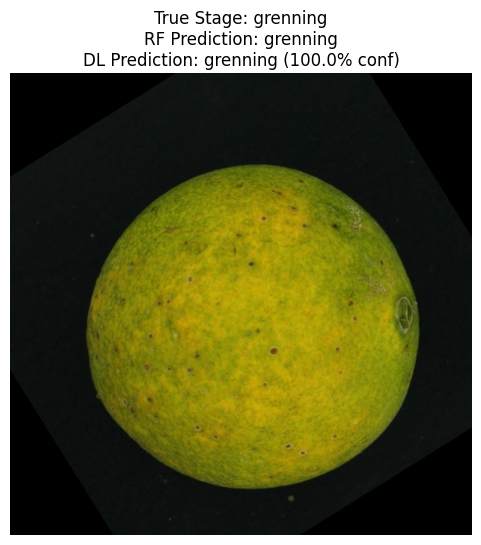

In [47]:
import random
import numpy as np
import matplotlib.pyplot as plt
import cv2
import glob
import os

# Select a random image from the test set
all_test_images = []
for cls in classes:
    all_test_images.extend(glob.glob(os.path.join(test_dir, cls, '*')))

sample_path = random.choice(all_test_images)
true_label_name = sample_path.split('/')[-2]

# 1. Prediction using Classical RF
feats = extract_features(sample_path)
rf_pred_idx = rf_classifier.predict([feats])[0]
rf_pred_name = classes[rf_pred_idx]

# 2. Prediction using Deep Learning (MobileNetV2)
img = cv2.imread(sample_path)
img_resized = cv2.resize(img, (224, 224)) / 255.0
img_expanded = np.expand_dims(img_resized, axis=0)
dl_pred_probs = dl_model.predict(img_expanded)[0]
dl_pred_idx = np.argmax(dl_pred_probs)
dl_pred_name = classes[dl_pred_idx]
dl_confidence = dl_pred_probs[dl_pred_idx] * 100

# Display the image and prediction results
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(6, 6))
plt.imshow(img_rgb)
plt.title(f"True Stage: {true_label_name}\nRF Prediction: {rf_pred_name}\nDL Prediction: {dl_pred_name} ({dl_confidence:.1f}% conf)")
plt.axis('off')
plt.show()

## 4. Single Image Inference Demonstration
Here we load a single example image from the test set, pass it through both the Classical ML and Deep Learning pipelines, and display the visual predictions side-by-side.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step


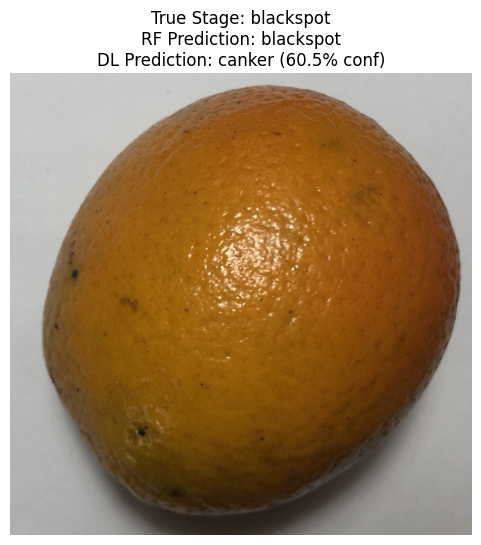

In [48]:
import random
import numpy as np
import matplotlib.pyplot as plt
import cv2
import glob
import os

# Select a random image from the test set
all_test_images = []
for cls in classes:
    all_test_images.extend(glob.glob(os.path.join(test_dir, cls, '*')))

sample_path = random.choice(all_test_images)
true_label_name = sample_path.split('/')[-2]

# 1. Prediction using Classical RF
feats = extract_features(sample_path)
rf_pred_idx = rf_classifier.predict([feats])[0]
rf_pred_name = classes[rf_pred_idx]

# 2. Prediction using Deep Learning (MobileNetV2)
img = cv2.imread(sample_path)
img_resized = cv2.resize(img, (224, 224)) / 255.0
img_expanded = np.expand_dims(img_resized, axis=0)
dl_pred_probs = dl_model.predict(img_expanded)[0]
dl_pred_idx = np.argmax(dl_pred_probs)
dl_pred_name = classes[dl_pred_idx]
dl_confidence = dl_pred_probs[dl_pred_idx] * 100

# Display the image and prediction results
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(6, 6))
plt.imshow(img_rgb)
plt.title(f"True Stage: {true_label_name}\nRF Prediction: {rf_pred_name}\nDL Prediction: {dl_pred_name} ({dl_confidence:.1f}% conf)")
plt.axis('off')
plt.show()

## 4. Single Image Inference Demonstration
Here we load a single example image from the test set, pass it through both the Classical ML and Deep Learning pipelines, and display the visual predictions side-by-side.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step


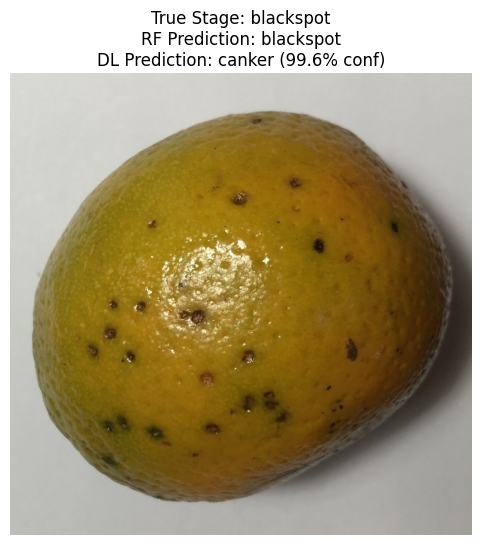

In [49]:
import random

# Select a random image from the test set
all_test_images = []
for cls in classes:
    all_test_images.extend(glob.glob(os.path.join(test_dir, cls, '*')))

sample_path = random.choice(all_test_images)
true_label_name = sample_path.split('/')[-2]

# 1. Prediction using Classical RF
feats = extract_features(sample_path)
rf_pred_idx = rf_classifier.predict([feats])[0]
rf_pred_name = classes[rf_pred_idx]

# 2. Prediction using Deep Learning (MobileNetV2)
img = cv2.imread(sample_path)
img_resized = cv2.resize(img, (224, 224)) / 255.0
img_expanded = np.expand_dims(img_resized, axis=0)
dl_pred_probs = dl_model.predict(img_expanded)[0]
dl_pred_idx = np.argmax(dl_pred_probs)
dl_pred_name = classes[dl_pred_idx]
dl_confidence = dl_pred_probs[dl_pred_idx] * 100

# Display the image and prediction results
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(6, 6))
plt.imshow(img_rgb)
plt.title(f"True Stage: {true_label_name}\nRF Prediction: {rf_pred_name}\nDL Prediction: {dl_pred_name} ({dl_confidence:.1f}% conf)")
plt.axis('off')
plt.show()

In [52]:
# Write training script for the Classical ML pipeline
classical_script = """import os
import glob
import cv2
import numpy as np
from skimage.feature import local_binary_pattern
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
import joblib

def extract_features(img_path):
    img = cv2.imread(img_path)
    if img is None:
        return None
    img_resized = cv2.resize(img, (128, 128))
    hsv = cv2.cvtColor(img_resized, cv2.COLOR_BGR2HSV)
    rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
    color_feats = []
    for i in range(3):
        color_feats.extend([np.mean(rgb[:,:,i]), np.std(rgb[:,:,i]), np.mean(hsv[:,:,i]), np.std(hsv[:,:,i])])
    gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)
    lbp = local_binary_pattern(gray, P=8, R=1, method='uniform')
    lbp_hist, _ = np.histogram(lbp.ravel(), bins=np.arange(0, 11), density=True)
    return np.hstack([color_feats, lbp_hist])

def train_pipeline():
    train_dir = 'avocado_data/train'
    test_dir = 'avocado_data/test'
    classes = sorted(os.listdir(train_dir))

    print("Extracting features...")
    X_train, y_train = [], []
    for label, cls in enumerate(classes):
        for p in glob.glob(os.path.join(train_dir, cls, '*')):
            feats = extract_features(p)
            if feats is not None:
                X_train.append(feats)
                y_train.append(label)

    X_test, y_test = [], []
    for label, cls in enumerate(classes):
        for p in glob.glob(os.path.join(test_dir, cls, '*')):
            feats = extract_features(p)
            if feats is not None:
                X_test.append(feats)
                y_test.append(label)

    rf = RandomForestClassifier(n_estimators=100, random_state=42)
    rf.fit(X_train, y_train)

    preds = rf.predict(X_test)
    print("Accuracy:", accuracy_score(y_test, preds))
    print(classification_report(y_test, preds, target_names=classes))

    # Save the trained model
    joblib.dump(rf, 'random_forest_model.joblib')
    print("Model saved to random_forest_model.joblib")

if __name__ == '__main__':
    train_pipeline()
"""

with open('train_classical.py', 'w') as f:
    f.write(classical_script)

print("Created train_classical.py for your GitHub repository!")

Created train_classical.py for your GitHub repository!


In [53]:
# Write training script for the Deep Learning pipeline
dl_script = """import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from sklearn.metrics import classification_report, accuracy_score

def train_dl_pipeline():
    train_dir = 'avocado_data/train'
    test_dir = 'avocado_data/test'
    classes = sorted(os.listdir(train_dir))

    # Generators
    train_datagen = ImageDataGenerator(
        rescale=1./255,
        rotation_range=20,
        width_shift_range=0.2,
        height_shift_range=0.2,
        horizontal_flip=True,
        fill_mode='nearest'
    )
    test_datagen = ImageDataGenerator(rescale=1./255)

    train_generator = train_datagen.flow_from_directory(
        train_dir,
        target_size=(224, 224),
        batch_size=32,
        class_mode='categorical',
        shuffle=True
    )

    test_generator = test_datagen.flow_from_directory(
        test_dir,
        target_size=(224, 224),
        batch_size=32,
        class_mode='categorical',
        shuffle=False
    )

    # Model
    base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    base_model.trainable = False

    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(0.2)(x)
    predictions = Dense(len(classes), activation='softmax')(x)

    model = Model(inputs=base_model.input, outputs=predictions)
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

    print("Training MobileNetV2 transfer learning model...")
    model.fit(train_generator, validation_data=test_generator, epochs=5, verbose=1)

    # Evaluate
    test_generator.reset()
    preds_probs = model.predict(test_generator)
    preds = np.argmax(preds_probs, axis=1)
    true = test_generator.classes

    print("\nAccuracy:", accuracy_score(true, preds))
    print(classification_report(true, preds, target_names=classes))

    # Save
    model.save('mobilenetv2_model.keras')
    print("Model saved to mobilenetv2_model.keras")

if __name__ == '__main__':
    train_dl_pipeline()
"""

with open('train_deep_learning.py', 'w') as f:
    f.write(dl_script)

print("Created train_deep_learning.py for your GitHub repository!")

Created train_deep_learning.py for your GitHub repository!


## 2. Approach 1: Classical Image Processing + Machine Learning (Random Forest)
Here we extract color statistics (Mean, Std Dev in HSV and RGB color spaces) and texture features (Local Binary Patterns) from the avocados to train a classic machine learning model.

In [40]:
import numpy as np
from skimage.feature import local_binary_pattern
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

def extract_features(img_path):
    img = cv2.imread(img_path)
    if img is None:
        return None
    img_resized = cv2.resize(img, (128, 128))

    # Color features: mean and std of RGB and HSV channels
    hsv = cv2.cvtColor(img_resized, cv2.COLOR_BGR2HSV)
    rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)

    color_feats = []
    for i in range(3):
        color_feats.append(np.mean(rgb[:,:,i]))
        color_feats.append(np.std(rgb[:,:,i]))
        color_feats.append(np.mean(hsv[:,:,i]))
        color_feats.append(np.std(hsv[:,:,i]))

    # Texture features: Local Binary Patterns on grayscale image
    gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)
    lbp = local_binary_pattern(gray, P=8, R=1, method='uniform')
    lbp_hist, _ = np.histogram(lbp.ravel(), bins=np.arange(0, 11), density=True)

    return np.hstack([color_feats, lbp_hist])

def load_dataset_features(data_dir):
    X, y = [], []
    for label, cls in enumerate(classes):
        cls_dir = os.path.join(data_dir, cls)
        for p in glob.glob(os.path.join(cls_dir, '*')):
            feats = extract_features(p)
            if feats is not None:
                X.append(feats)
                y.append(label)
    return np.array(X), np.array(y)

In [41]:
print("Extracting features for Training and Testing sets...")
X_train, y_train = load_dataset_features(train_dir)
X_test, y_test = load_dataset_features(test_dir)

print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

# Train Random Forest
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier.fit(X_train, y_train)

# Predict and Evaluate
y_pred = rf_classifier.predict(X_test)
print("\n--- Classical ML Approach (Random Forest) Evaluation ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(classification_report(y_test, y_pred, target_names=classes))

Extracting features for Training and Testing sets...
Train shape: (991, 22), Test shape: (99, 22)

--- Classical ML Approach (Random Forest) Evaluation ---
Accuracy: 0.9697
              precision    recall  f1-score   support

      canker       1.00      0.86      0.93        22
       fresh       1.00      1.00      1.00        33
   blackspot       0.88      1.00      0.94        22
    grenning       1.00      1.00      1.00        22

    accuracy                           0.97        99
   macro avg       0.97      0.97      0.97        99
weighted avg       0.97      0.97      0.97        99



## 3. Approach 2: Deep Learning (MobileNetV2 Transfer Learning)
Next, we'll design a Deep Learning pipeline. We'll use MobileNetV2, an efficient and lightweight architecture ideal for mobile/production systems, and fine-tune it on our Avocado dataset.

In [42]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model

# Define data generators with basic augmentation for the training set
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

Found 991 images belonging to 4 classes.
Found 99 images belonging to 4 classes.


In [43]:
# Build MobileNetV2 transfer learning model
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False  # Freeze convolutional base

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.2)(x)
predictions = Dense(len(classes), activation='softmax')(x)

dl_model = Model(inputs=base_model.input, outputs=predictions)
dl_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train model
history = dl_model.fit(
    train_generator,
    validation_data=test_generator,
    epochs=10,
    verbose=1
)

Epoch 1/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 71s 2s/step - accuracy: 0.8678 - loss: 0.3294 - val_accuracy: 0.9091 - val_loss: 0.1739
Epoch 2/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 64s 2s/step - accuracy: 0.9707 - loss: 0.0752 - val_accuracy: 0.9091 - val_loss: 0.1807
Epoch 3/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 94s 2s/step - accuracy: 0.9808 - loss: 0.0491 - val_accuracy: 0.9091 - val_loss: 0.1572
Epoch 4/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 64s 2s/step - accuracy: 0.9839 - loss: 0.0465 - val_accuracy: 0.9192 - val_loss: 0.1479
Epoch 5/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 63s 2s/step - accuracy: 0.9788 - loss: 0.0480 - val_accuracy: 0.9192 - val_loss: 0.1782
Epoch 6/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 64s 2s/step - accuracy: 0.9849 - loss: 0.0403 - val_accuracy: 0.9394 - val_loss: 0.1390
Epoch 7/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 64s 2s/step - accuracy: 0.9869 - loss: 0.0447 - val_accuracy: 0.9293 - val_loss: 0.1417
Epoch 8/10
31/31 ━━━━━━━━━━━━━━━━━━━━ 65s 2s/step - accuracy: 0.9859 - loss: 0.0398 - val_accuracy: 0.9596 - val_loss:

In [44]:
# Evaluate the Deep Learning Model
test_generator.reset()
predictions_dl = dl_model.predict(test_generator)
y_pred_dl = np.argmax(predictions_dl, axis=1)
y_true_dl = test_generator.classes

print("\n--- Deep Learning Approach (MobileNetV2) Evaluation ---")
print(f"Accuracy: {accuracy_score(y_true_dl, y_pred_dl):.4f}")
print(classification_report(y_true_dl, y_pred_dl, target_names=classes))

4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step

--- Deep Learning Approach (MobileNetV2) Evaluation ---
Accuracy: 0.9394
              precision    recall  f1-score   support

      canker       0.95      0.86      0.90        22
       fresh       0.81      0.95      0.88        22
   blackspot       1.00      0.94      0.97        33
    grenning       1.00      1.00      1.00        22

    accuracy                           0.94        99
   macro avg       0.94      0.94      0.94        99
weighted avg       0.95      0.94      0.94        99



## 2. Approach 1: Classical Image Processing + Machine Learning (Random Forest)
Here we extract color statistics (Mean, Std Dev in HSV and RGB color spaces) and texture features (Local Binary Patterns) from the avocados to train a classic machine learning model.

In [45]:
import numpy as np
from skimage.feature import local_binary_pattern
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

def extract_features(img_path):
    img = cv2.imread(img_path)
    if img is None:
        return None
    img_resized = cv2.resize(img, (128, 128))

    # Color features: mean and std of RGB and HSV channels
    hsv = cv2.cvtColor(img_resized, cv2.COLOR_BGR2HSV)
    rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)

    color_feats = []
    for i in range(3):
        color_feats.append(np.mean(rgb[:,:,i]))
        color_feats.append(np.std(rgb[:,:,i]))
        color_feats.append(np.mean(hsv[:,:,i]))
        color_feats.append(np.std(hsv[:,:,i]))

    # Texture features: Local Binary Patterns on grayscale image
    gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)
    lbp = local_binary_pattern(gray, P=8, R=1, method='uniform')
    lbp_hist, _ = np.histogram(lbp.ravel(), bins=np.arange(0, 11), density=True)

    return np.hstack([color_feats, lbp_hist])

def load_dataset_features(data_dir):
    X, y = [], []
    for label, cls in enumerate(classes):
        cls_dir = os.path.join(data_dir, cls)
        for p in glob.glob(os.path.join(cls_dir, '*')):
            feats = extract_features(p)
            if feats is not None:
                X.append(feats)
                y.append(label)
    return np.array(X), np.array(y)

In [46]:
print("Extracting features for Training and Testing sets...")
X_train, y_train = load_dataset_features(train_dir)
X_test, y_test = load_dataset_features(test_dir)

print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

# Train Random Forest
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier.fit(X_train, y_train)

# Predict and Evaluate
y_pred = rf_classifier.predict(X_test)
print("\n--- Classical ML Approach (Random Forest) Evaluation ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(classification_report(y_test, y_pred, target_names=classes))

Extracting features for Training and Testing sets...
Train shape: (991, 22), Test shape: (99, 22)

--- Classical ML Approach (Random Forest) Evaluation ---
Accuracy: 0.9697
              precision    recall  f1-score   support

      canker       1.00      0.86      0.93        22
       fresh       1.00      1.00      1.00        33
   blackspot       0.88      1.00      0.94        22
    grenning       1.00      1.00      1.00        22

    accuracy                           0.97        99
   macro avg       0.97      0.97      0.97        99
weighted avg       0.97      0.97      0.97        99

